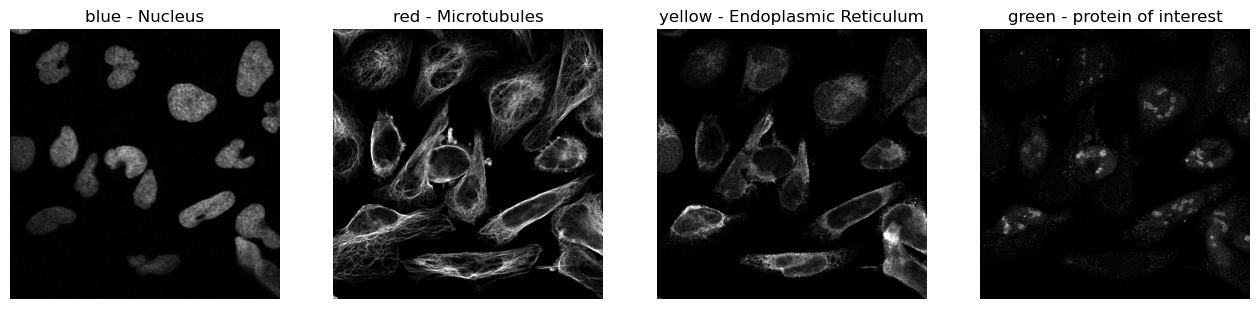

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Load the images
blue = mpimg.imread("protein_loc_project_data/0001_blue.png")
red = mpimg.imread("protein_loc_project_data/0001_red.png")
yellow = mpimg.imread("protein_loc_project_data/0001_yellow.png")
green = mpimg.imread("protein_loc_project_data/0001_green.png")

# Display the image
fig1 = plt.figure(figsize=(16,4))
axs = fig1.subplots(1,4)
axs = np.reshape(axs, np.prod(axs.shape)) if len(np.array(axs).shape)!=0 else np.array([axs])
axs[0].imshow(blue, cmap='gray')
axs[0].set_title('blue - Nucleus')
axs[0].axis('off')  # Hide the axis
axs[1].imshow(red, cmap='gray')
axs[1].set_title('red - Microtubules')
axs[1].axis('off')  # Hide the axis
axs[2].imshow(yellow, cmap='gray')
axs[2].set_title('yellow - Endoplasmic Reticulum')
axs[2].axis('off')  # Hide the axis
axs[3].imshow(green, cmap='gray')
axs[3].set_title('green - protein of interest')
axs[3].axis('off')  # Hide the axis
plt.show()

In [2]:
import pandas as pd

df = pd.read_csv("training_labels_protein_loc.csv", dtype={"sample_id": str})
display(df)
print(df.dtypes)

LABELS = ["Nucleoli", "Mitochondria"]    # fixed column order used everywhere

labeled = df.dropna(subset=LABELS).reset_index(drop=True)
unlabeled  = df[df[LABELS].isna().any(axis=1)].reset_index(drop=True)

print(len(labeled), len(unlabeled))             # expect 1200 and 602

labeled_ids = labeled["sample_id"].tolist()  # keep IDs separate from labels
unlabeled_ids  = unlabeled["sample_id"].tolist()

y_nn_labeled = labeled[LABELS].astype("float32").to_numpy()# (1200, 2), float32
y_nn_unlabeled = unlabeled[LABELS].astype("float32").to_numpy()
# test labels are all NaN (unlabeled), so there is no y for the test set

print(y_nn_labeled.shape, y_nn_labeled.dtype)
print(y_nn_unlabeled.shape, y_nn_unlabeled.dtype)
assert not np.isnan(y_nn_labeled).any()
print(y_nn_labeled[:3])                   # 0001-0003 should be [1., 0.]
print(y_nn_unlabeled[:3]) 

,sample_id,Mitochondria,Nucleoli
0,0001,0.0,1.0
1,0002,0.0,1.0
2,0003,0.0,1.0
3,0004,0.0,1.0
4,0005,1.0,0.0
...,...,...,...
1797,1798,NaN,NaN
1798,1799,NaN,NaN
1799,1800,NaN,NaN
1800,1801,NaN,NaN


sample_id        object
Mitochondria    float64
Nucleoli        float64
dtype: object
1200 602
(1200, 2) float32
(602, 2) float32
[[1. 0.]
 [1. 0.]
 [1. 0.]]
[[nan nan]
 [nan nan]
 [nan nan]]


In [3]:
#Normalize and Stack images
ROOT = "protein_loc_project_data"       
F, T = 2, 512
CHANNELS = ["blue", "red", "yellow", "green"]   

def norm_channel(x, lo=1, hi=99.5):
    """Per-image percentile normalization to 0-1."""
    a, b = np.percentile(x, [lo, hi])
    return np.clip((x - a) / (b - a + 1e-8), 0, 1)

def load_sample(sid, root):
    chans = []
    for c in CHANNELS:
        img = mpimg.imread(f"{root}/{sid}_{c}.png").astype("float32")
        if img.ndim == 3:            # some PNGs load as RGB(A); take one channel
            img = img[..., 0]
        chans.append(norm_channel(img))
    return np.stack(chans, axis=0)   # (4, H, W)

x = load_sample("0003", "protein_loc_project_data")
print(x.shape, x.dtype, x.min(), x.max())

(4, 2048, 2048) float32 0.0 1.0


In [4]:
from PIL import Image
import pandas as pd

root = "protein_loc_project_data"
sizes = [Image.open(f"{root}/{sid}_green.png").size for sid in labeled["sample_id"]]
labeled["img_size"] = [f"{w}x{h}" for w, h in sizes]

print(labeled["img_size"].value_counts())
print(pd.crosstab(labeled["img_size"], [labeled["Nucleoli"],labeled["Mitochondria"]]))

img_size
2048x2048    924
1728x1728    242
3072x3072     34
Name: count, dtype: int64
Nucleoli      0.0  1.0    
Mitochondria  1.0  0.0 1.0
img_size                  
1728x1728     184   52   6
2048x2048     651  241  32
3072x3072      28    2   4


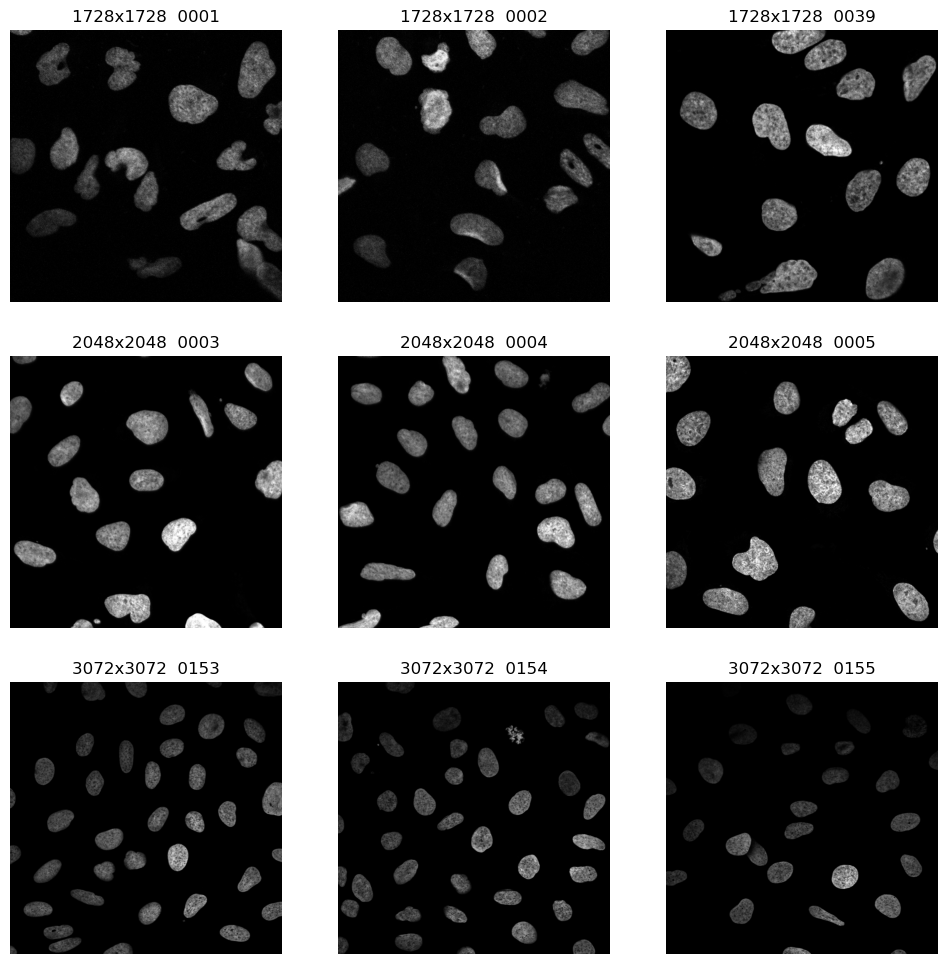

In [5]:
fig, axs = plt.subplots(3, 3, figsize=(12, 12))
for r, size in enumerate(["1728x1728", "2048x2048", "3072x3072"]):
    for c, sid in enumerate(labeled[labeled.img_size == size]["sample_id"].iloc[:3]):
        axs[r, c].imshow(mpimg.imread(f"{root}/{sid}_blue.png"), cmap="gray")
        axs[r, c].set_title(f"{size}  {sid}"); axs[r, c].axis("off")

In [6]:
import numpy as np
from PIL import Image

root = "protein_loc_project_data"
F, T = 2, 512
CHANNELS = ["blue", "red", "yellow", "green"]

def norm_channel(x, lo=1, hi=99.5):
    a, b = np.percentile(x, [lo, hi])
    return np.clip((x - a) / (b - a + 1e-8), 0, 1)

def load_sample(sid, root=root, f=F):
    chans = []
    for c in CHANNELS:
        img = np.array(Image.open(f"{root}/{sid}_{c}.png"), dtype="float32")
        if img.ndim == 3:
            img = img[..., 0]
        h, w = img.shape
        img = img[: h // f * f, : w // f * f]
        img = img.reshape(h // f, f, w // f, f).mean(axis=(1, 3))   # 2x block average
        chans.append(norm_channel(img))
    return np.stack(chans)                 # (4, H/f, W/f)

# test in the main process before any Pool
x = load_sample(labeled_ids[0])
print(x.shape, x.dtype, x.min(), x.max())  # expect (4, 864, 864) (or 1024/1536), float32, 0.0 to 1.0

(4, 864, 864) float32 0.0 1.0


In [7]:
import os
from multiprocessing import Pool
from tqdm import tqdm
from pathlib import Path
import numpy as np
from PIL import Image

F, T = 2, 512        # F = downsample factor, T = tile size
CHANNELS = ["blue", "red", "yellow", "green"]


out = os.path.expanduser("~/scratch/BMED3201/protein_loc")
os.makedirs(out, exist_ok=True)

def tiles_for(i):
    x = load_sample(labeled_ids[i])
    _, H, W = x.shape
    nr, nc = H // T, W // T
    r0, c0 = (H - nr * T) // 2, (W - nc * T) // 2        # centered grid
    tiles = [x[:, r0 + r*T : r0 + (r+1)*T, c0 + c*T : c0 + (c+1)*T]
             for r in range(nr) for c in range(nc)]
    return i, np.stack(tiles).astype("float16")

# tile counts (header-only)
counts = []
for sid in labeled_ids:
    w, h = Image.open(f"{root}/{sid}_green.png").size
    counts.append((h // F // T) * (w // F // T))
n_tiles = sum(counts)

X = np.lib.format.open_memmap(f"{out}/X_labeled.npy", mode="w+",
                              dtype="float16", shape=(n_tiles, 4, T, T))
img_idx = np.repeat(np.arange(len(labeled_ids)), counts).astype("int32")
offsets = np.concatenate([[0], np.cumsum(counts)])

n_proc = int(os.environ.get("SLURM_CPUS_ON_NODE", os.cpu_count()))
with Pool(n_proc) as p:
    for i, tiles in tqdm(p.imap_unordered(tiles_for, range(len(labeled_ids))), total=len(labeled_ids)):
        X[offsets[i]:offsets[i+1]] = tiles
X.flush()

np.save(f"{out}/img_idx_all.npy", img_idx)
np.save(f"{out}/y_nn_labeled.npy", y_nn_labeled)

100%|██████████| 1200/1200 [01:33<00:00, 12.84it/s]


In [8]:
dataX = np.load('X_labeled.npy')
dataY = np.load('y_nn_labeled.npy', allow_pickle=True)
img_idx = np.load('img_idx_all.npy')

y_tiles = dataY[img_idx]

print(dataX.shape, y_tiles.shape)
assert len(dataX) == len(y_tiles)


(4244, 4, 512, 512) (4244, 2)


In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader,TensorDataset, random_split

In [10]:
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backend.mps.is_available()
    else "cpu"
)

print(f"Using {device} device")

Using cuda device


In [11]:
#Convert nmpy arrays to tensor and split.
x_tensor = torch.tensor(dataX)
y_tensor = torch.tensor(y_tiles)
dataset = TensorDataset(x_tensor, y_tensor)
print(len(dataset))


#Split train/validation
trainval_size = int(.80 * len(dataset))
test_size = len(dataset) - trainval_size

generator = torch.Generator().manual_seed(41)
trainval_dataset, test_dataset = random_split(dataset, [trainval_size, test_size], generator=generator)

train_size = int(.83 * len(trainval_dataset))
val_size = len(trainval_dataset) - train_size

train_dataset, val_dataset = random_split(trainval_dataset, [train_size, val_size], generator=generator)


train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)




4244


In [16]:
#Build model
class proteinLocCNN(nn.Module):
    def __init__(self, num_classes = 2):
        super(proteinLocCNN, self).__init__()
        
        self.conv1 = nn.Conv2d(in_channels=4, out_channels=32, kernel_size=4)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=4)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=4)
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=4)
        self.conv5 = nn.Conv2d(in_channels=256, out_channels=512, kernel_size=4)
        
        self.bn1 = nn.BatchNorm2d(32)
        self.bn2 = nn.BatchNorm2d(64)
        self.bn3 = nn.BatchNorm2d(128)
        self.bn4 = nn.BatchNorm2d(256)
        self.bn5 = nn.BatchNorm2d(512)
    
        self.flatten = nn.Flatten()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        
        
        self.fc1 = nn.Linear(512*1*1,128)
        self.fc2 = nn.Linear(128, num_classes)
    def forward(self,x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = self.pool(F.relu(self.bn5(self.conv5(x))))
         
        x = F.relu(self.gap(x))
        
        x = self.flatten(x)
        
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        
        return x

criterion = torch.nn.BCEWithLogitsLoss()

def trainer(loader, model):
    optimizer = torch.optim.SGD(model.parameters(), lr=.0005)
    model.train()
    for batch_idx, (X_batch, y_batch) in enumerate(loader):
            X_batch = X_batch.to(device, non_blocking=True).float()
            y_batch = y_batch.to(device, non_blocking=True)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
def val(loader, model):
    model.eval()
    val_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device).float()
            labels = labels.to(device)

            outputs = model(images)
            val_loss += criterion(outputs, labels).item() * images.size(0)

            preds = (torch.sigmoid(outputs) > 0.5).float()   # [B, 2]
            correct += (preds == labels).all(dim=1).sum().item()  # exact match on both labels
            total += labels.size(0)

    avg_loss = val_loss / total
    accuracy = correct / total * 100
    print(f" Validation - Loss: {avg_loss:.4f}, Accuracy {accuracy:.2f}%")
    return avg_loss, accuracy


def test(loader, model, name):
    model.load_state_dict(torch.load(name))
    return val(loader, model)
    
    



In [17]:
#Training model

PLmodel = proteinLocCNN(num_classes = 2).to(device)

best_val_loss = float('inf')
for epoch in range(100):
    trainer(train_loader, PLmodel)
    val_loss, accuracy = val(val_loader, PLmodel)
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(PLmodel.state_dict(), 'best_cnn_model.pth')
        print(f"best new model saved at {epoch + 1}!")

 Validation - Loss: 0.5806, Accuracy 68.86%
best new model saved at 1!
 Validation - Loss: 0.5381, Accuracy 70.93%
best new model saved at 2!
 Validation - Loss: 0.5098, Accuracy 71.45%
best new model saved at 3!
 Validation - Loss: 0.4778, Accuracy 74.57%
best new model saved at 4!
 Validation - Loss: 0.4502, Accuracy 78.03%
best new model saved at 5!
 Validation - Loss: 0.4197, Accuracy 79.93%
best new model saved at 6!
 Validation - Loss: 0.3930, Accuracy 82.87%
best new model saved at 7!
 Validation - Loss: 0.3557, Accuracy 85.99%
best new model saved at 8!
 Validation - Loss: 0.3308, Accuracy 84.95%
best new model saved at 9!
 Validation - Loss: 0.3108, Accuracy 88.24%
best new model saved at 10!
 Validation - Loss: 0.2846, Accuracy 88.58%
best new model saved at 11!
 Validation - Loss: 0.2714, Accuracy 89.10%
best new model saved at 12!
 Validation - Loss: 0.2696, Accuracy 91.18%
best new model saved at 13!
 Validation - Loss: 0.2459, Accuracy 90.83%
best new model saved at 14!
 

In [18]:
test_loss, test_accuracy = test(test_loader, PLmodel, 'best_cnn_model.pth')
print(f"Best model test loss: {test_loss}. Best model test accuracy: {test_accuracy}%")

 Validation - Loss: 0.1203, Accuracy 94.58%
Best model test loss: 0.12031251954044203. Best model test accuracy: 94.58186101295641%
